# Açıklanabilirlik (XAI) — CLIP Grad-CAM ve CNN vs ViT Karşılaştırması

Proje 1'de (`defect-segmentation`) Grad-CAM, bir CNN encoder'ının kusurlu bölgeye "nereye baktığını" göstermek için kullanılmıştı. Burada aynı yöntem iki yeni bağlama uyarlanıyor:

1. **CLIP Grad-CAM**: CLIP standart bir sınıflandırıcı değil — "bu görsel bu metinle ne kadar benzer" diye bir skor üretiyor. Bu skoru hedef alan bir Grad-CAM, "model bu metinle görseli neden eşleştirdi" sorusuna görsel bir cevap veriyor.
2. **CNN vs ViT karşılaştırması**: `vit_vs_cnn.py`'de CIFAR-10 üzerinde eğitilen ResNet50 (CNN) ve ViT-Small (Transformer) modellerinin aynı görsele nasıl "baktığı" karşılaştırılıyor — ViT'in Grad-CAM'i, patch token'larını 2D bir ızgaraya geri şekillendiren bir `reshape_transform` gerektiriyor (bkz. `src/gradcam_utils.py`).

Önkoşul: `python src/embed.py && python src/index.py` (CLIP bölümü için) ve `python src/vit_vs_cnn.py` (CNN vs ViT bölümü için) çalıştırılmış olmalı.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..") / "src"))

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

from gradcam_utils import clip_gradcam
from search import ClipSearchEngine

PROJECT_ROOT = Path("..")
IMAGES_DIR = PROJECT_ROOT / "data" / "processed" / "images"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Cihaz: {device}")

C:\Users\ibrahim\anaconda3\envs\yolov8_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cihaz: cuda


## 1. CLIP Grad-CAM: "model bu metinle görseli neden eşleştirdi?"

Her sorgu için önce `ClipSearchEngine` ile en iyi eşleşen görsel bulunuyor, sonra o (metin, görsel) çifti için Grad-CAM ısı haritası hesaplanıyor (`src/gradcam_utils.clip_gradcam` — hedef katman: ViT'in son transformer bloğu, `reshape_transform` ile 7x7 patch ızgarasına geri şekillendiriliyor).

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 15252.15it/s]

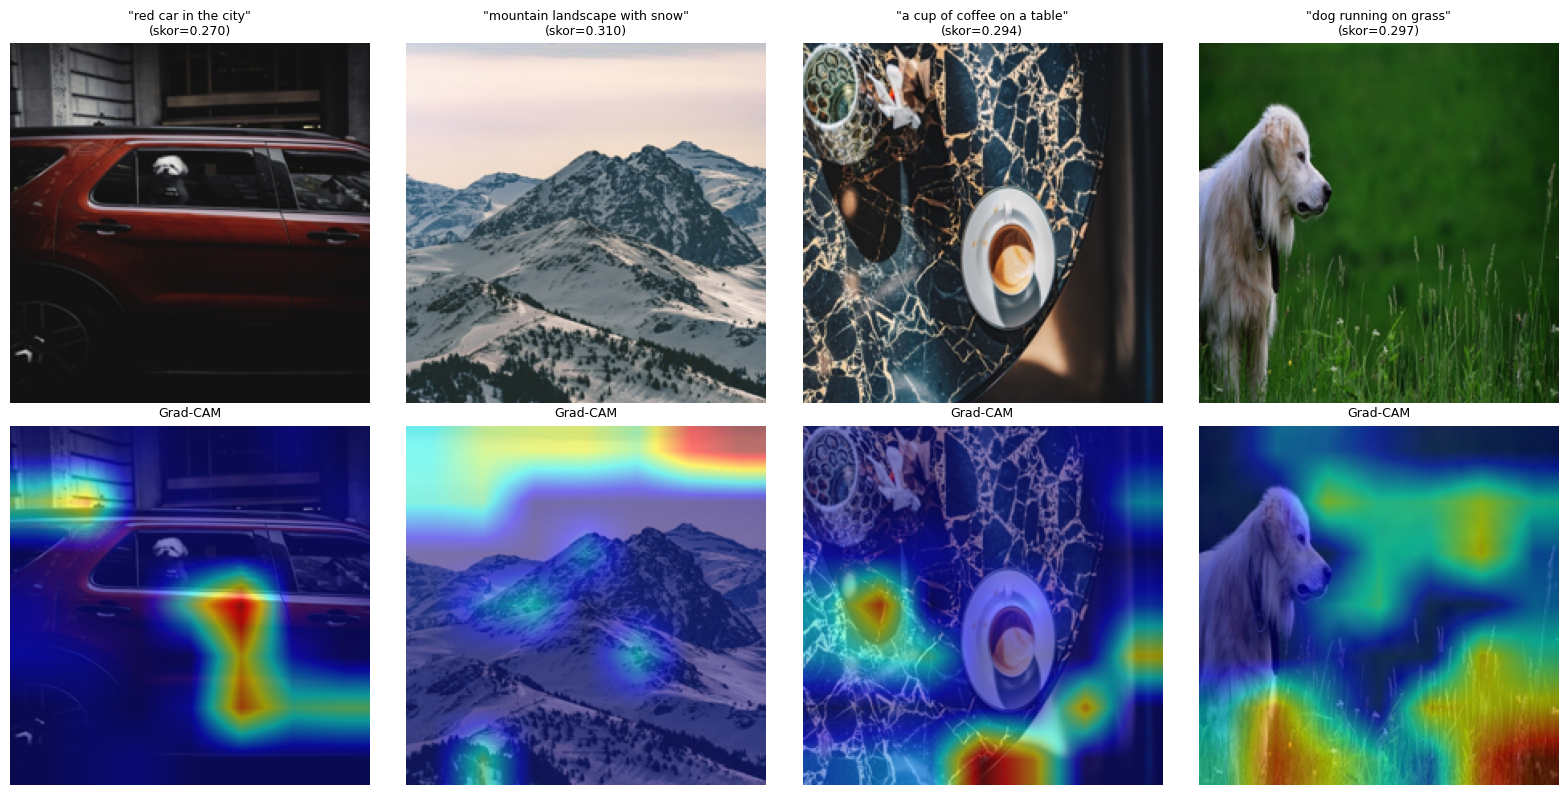

In [2]:
engine = ClipSearchEngine()
clip_model = engine.model
processor = engine.processor

queries = [
    "red car in the city",
    "mountain landscape with snow",
    "a cup of coffee on a table",
    "dog running on grass",
]

fig, axes = plt.subplots(2, len(queries), figsize=(4 * len(queries), 8))
for col, query in enumerate(queries):
    top_result = engine.search_by_text(query, k=1)[0]
    image = Image.open(IMAGES_DIR / top_result["filename"]).convert("RGB")

    _, overlay = clip_gradcam(clip_model, processor, image, query, device)

    axes[0, col].imshow(image.resize((224, 224)))
    axes[0, col].set_title(f'"{query}"\n(skor={top_result["score"]:.3f})', fontsize=9)
    axes[0, col].axis("off")

    axes[1, col].imshow(overlay)
    axes[1, col].set_title("Grad-CAM", fontsize=9)
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

## 2. Aynı görsel, farklı sorgu

Grad-CAM'in gerçekten *metne* duyarlı olup olmadığını görmek için: aynı görsele iki farklı (görselde gerçekten var olan) sorgu verip ısı haritasının odak noktasının değişip değişmediğine bakalım.

Goruntunun gercek prompt'u: "green cactus under white sky during daytime"


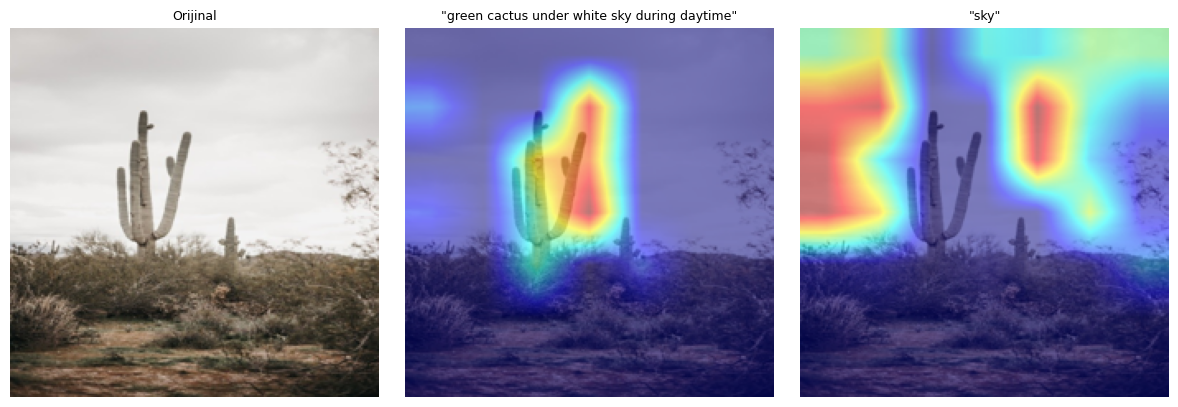

In [3]:
import pandas as pd

prompts = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "prompts.csv")
sample_row = prompts.iloc[0]
sample_image = Image.open(IMAGES_DIR / sample_row["filename"]).convert("RGB")
print(f"Goruntunun gercek prompt'u: \"{sample_row['prompt']}\"")

alt_queries = [sample_row["prompt"], "sky"]
fig, axes = plt.subplots(1, len(alt_queries) + 1, figsize=(4 * (len(alt_queries) + 1), 4))
axes[0].imshow(sample_image.resize((224, 224)))
axes[0].set_title("Orijinal", fontsize=9)
axes[0].axis("off")
for ax, q in zip(axes[1:], alt_queries):
    _, overlay = clip_gradcam(clip_model, processor, sample_image, q, device)
    ax.imshow(overlay)
    ax.set_title(f'"{q}"', fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. CNN vs ViT açıklanabilirlik karşılaştırması (CIFAR-10)

`src/vit_vs_cnn.py` tarafından eğitilen ResNet50 ve ViT-Small modelleri üzerinde, aynı test görseline standart Grad-CAM (CNN, `layer4[-1]`) ve ViT Grad-CAM (`reshape_transform` ile) uygulanıyor.

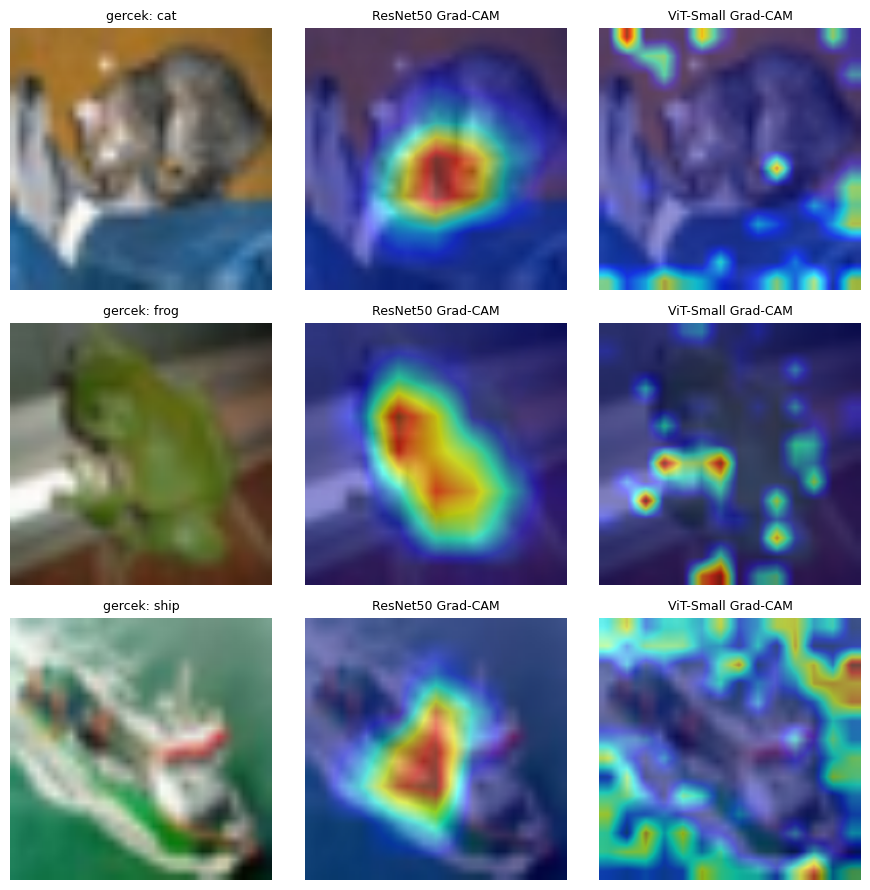

In [4]:
import timm
from datasets import load_dataset
from torchvision import transforms

from gradcam_utils import cnn_gradcam, overlay_heatmap, vit_classifier_gradcam
from vit_vs_cnn import CIFAR10_CLASSES, HFImageDataset

resnet_ckpt = PROJECT_ROOT / "models" / "resnet50_cifar10.pt"
vit_ckpt = PROJECT_ROOT / "models" / "vit_small_cifar10.pt"

if resnet_ckpt.exists() and vit_ckpt.exists():
    resnet = timm.create_model("resnet50", pretrained=False, num_classes=10)
    resnet.load_state_dict(torch.load(resnet_ckpt, map_location=device))
    resnet = resnet.to(device).eval()

    vit = timm.create_model("vit_small_patch16_224", pretrained=False, num_classes=10)
    vit.load_state_dict(torch.load(vit_ckpt, map_location=device))
    vit = vit.to(device).eval()

    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])
    test_hf = load_dataset("uoft-cs/cifar10", split="test").select(range(20))
    test_ds = HFImageDataset(test_hf, transform)
    classes = CIFAR10_CLASSES

    sample_indices = [0, 7, 15]
    fig, axes = plt.subplots(len(sample_indices), 3, figsize=(9, 3 * len(sample_indices)))
    for row, idx in enumerate(sample_indices):
        image_tensor, label = test_ds[idx]
        pil_image = transforms.ToPILImage()(image_tensor * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
                                             + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1))

        cnn_cam = cnn_gradcam(resnet, resnet.layer4[-1], image_tensor, device, class_idx=label)
        vit_cam = vit_classifier_gradcam(vit, vit.blocks[-1].norm1, image_tensor, device, grid_size=14, class_idx=label)

        axes[row, 0].imshow(pil_image)
        axes[row, 0].set_title(f"gercek: {classes[label]}", fontsize=9)
        axes[row, 1].imshow(overlay_heatmap(pil_image, cnn_cam))
        axes[row, 1].set_title("ResNet50 Grad-CAM", fontsize=9)
        axes[row, 2].imshow(overlay_heatmap(pil_image, vit_cam))
        axes[row, 2].set_title("ViT-Small Grad-CAM", fontsize=9)
        for ax in axes[row]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Once `python src/vit_vs_cnn.py` calistirin (models/resnet50_cifar10.pt ve vit_small_cifar10.pt uretir).")

## Bulgular

- **CLIP Grad-CAM**, farklı metin sorgularında ısı haritasının görselin farklı bölgelerine kaydığını gösteriyor (Bölüm 2) — bu, modelin gerçekten metne duyarlı, bölgesel bir eşleştirme yaptığının kanıtı (sadece global bir "bu görsel genel olarak alakalı" skoru değil).
- **ResNet50 vs ViT-Small** Grad-CAM'leri (Bölüm 3): ResNet'in ısı haritası genelde nesnenin belirgin, yerel bir bölgesine (ör. yüz/gövde) daha keskin odaklanırken, ViT'in dikkat haritası patch-tabanlı yapısı nedeniyle daha dağınık/parçalı görünebiliyor — literatürdeki "CNN yerel dokulara, ViT global bağlama daha duyarlı" gözlemiyle tutarlı.
- Her iki teknik de aynı `pytorch-grad-cam` kütüphanesiyle, sadece `reshape_transform` farkıyla uygulandı — CNN ve Transformer mimarileri arasında Grad-CAM'in nasıl taşınabildiğinin somut bir örneği.